# P9 - Đánh giá hallucination / groundedness cho KGQA (WebQSP, pool ReaRev)

Notebook này chạy **offline** trên records reader đã có từ P8 cell 08 (`results_gnn/b08_reader_*`, `b08g_reader_*`), không gọi lại LLM. Nó tách hai khái niệm:

- **Faithfulness**: câu trả lời có được graph evidence đã đưa cho reader hỗ trợ (entailed) hay không.
- **Correctness**: câu trả lời có đúng gold hay không.

Mỗi entity trong câu trả lời là một *claim*. Verifier hai tầng (`kgqa_bench/hallucination.py`):

| Tầng | Kiểm tra | Kết quả |
|---|---|---|
| 1 (deterministic) | entity là đích của path topic -> entity trong context đã chọn | `path_endpoint` |
| 1 | entity chỉ xuất hiện làm node trung gian | `in_context_no_proof` -> UNSUPPORTED |
| 1 | entity có trong subgraph nhưng không được retrieve | `in_subgraph_only` -> UNSUPPORTED |
| 1 | entity không có trong subgraph | `absent` -> UNSUPPORTED |
| 2 (semantic) | chuỗi quan hệ có hướng của path trùng reference proof (topic -> gold, chỉ dùng lúc đánh giá) hoặc entity là gold | SUPPORTED, ngược lại UNCERTAIN |
| 2 (tuỳ chọn) | LLM judge cho claim UNCERTAIN | SUPPORTED / CONTRADICTED / UNCERTAIN |

Nhãn cấp câu: `hallucinated` = có claim UNSUPPORTED hoặc CONTRADICTED; `hallucinated_strict` tính thêm UNCERTAIN. Abstention (`unknown`, `cannot determine`) không bị tính là hallucination.

Ba nhóm metric:

- **A. Faithfulness**: entity_unsupported_rate (proxy cũ), claim_hallucination_rate (CHR), question_hallucination_rate (QHR), graph_proof_support_rate, contradiction_rate, uncertain_rate.
- **B. Correctness**: llm_hit, llm_f1, grounded_correct_rate, grounded_answer_f1, correct_ungrounded_rate, abstention_rate, answer_coverage.
- **C. Risk**: đường risk-coverage xếp theo confidence của retriever cho hallucination và cho trả lời sai, AURC và risk tại các mức coverage.

Thứ tự chạy: 00 -> 01 -> 02 (bắt buộc), 03-09 phân tích, 10 judge (tuỳ chọn, cần GPU), 11 human review, 12 tổng kết.

In [1]:
# ==== 00. Mount Drive + đường dẫn ====
from google.colab import drive; drive.mount('/content/drive')
DRIVE_BASE = '/content/drive/MyDrive/ThS/Research/colab'
GRAPH_RAG  = f'{DRIVE_BASE}/graph_rag'
import os, sys, json, glob, shutil, time, subprocess
os.environ['PYTHONDONTWRITEBYTECODE'] = '1'; sys.dont_write_bytecode = True
for d in glob.glob(f'{GRAPH_RAG}/**/__pycache__', recursive=True): shutil.rmtree(d, ignore_errors=True)
os.chdir(GRAPH_RAG); sys.path.insert(0, GRAPH_RAG)
!pip install -q datasets sentence-transformers transformers accelerate networkx tqdm matplotlib tabulate
# chạy lại trong cùng phiên: bỏ module cũ khỏi bộ nhớ để import đúng bản vừa sync lên Drive
for _m in [m for m in sys.modules if m.split('.')[0] in ('kgqa_bench', 'prism')]: del sys.modules[_m]
import numpy as np, pandas as pd
from IPython.display import Image, display
from kgqa_bench import hallucination as H
from kgqa_bench import escalation as E
from kgqa_bench.data import load_spec
import prism.qa_text_eval as _qa
assert hasattr(_qa, 'split_answer'), 'prism/qa_text_eval.py trên Drive là bản cũ -> sync lại (commit be5472e)'
assert _qa.split_answer('Based on the paths, the answer is:\n* Mobile')[0] == ['Mobile'], 'parser cũ vẫn đang được dùng'
print('cwd =', os.getcwd(), '| hallucination module OK | parser be5472e OK')

Mounted at /content/drive
cwd = /content/drive/MyDrive/ThS/Research/colab/graph_rag | hallucination module OK | parser be5472e OK


## 01 - Cấu hình: thư mục records, dataset spec, method, judge
`RESULTS` là thư mục kết quả của P8 (`results_gnn`). Mỗi thư mục `b08_reader_<model>` (prompt gốc) hoặc `b08g_reader_<model>` (prompt grounded), có hậu tố `_v3` nếu P8 chọn CGAR v3. `WEBQSP_TE` phải đúng spec đã dùng ở P8 để map qid về subgraph.

In [2]:
RESULTS   = f'{GRAPH_RAG}/results_gnn'
CKPT      = f'{GRAPH_RAG}/ckpt'
WEBQSP_TE = f'gnnrag:{CKPT}/gnn_features_webqsp_test.pkl:webqsp:test'
METHODS   = ['gnnrag_all', 'gnnrag_top5', 'sbert_top5', 'cgar', 'cgar_esc']   # cgar_esc chỉ có trong b08c/b08f (CGAR-G); thư mục thiếu method thì bỏ qua
REF       = 'gnnrag_all'
STRICT    = False          # True: UNCERTAIN cũng tính là hallucination (báo cả hai trong report)
JUDGE     = None           # ví dụ 'hf:Qwen/Qwen2.5-7B-Instruct' cho cell 10
REVIEW_N  = 200            # số dòng cho human review
READER_DIRS = sorted(d for d in glob.glob(f'{RESULTS}/b08*_reader_*') if os.path.exists(f'{d}/results.json'))
assert READER_DIRS, 'chưa có thư mục b08_reader_* với results.json -> chạy P8 cell 08 trước'
PREFIX = {'b08g': 'grounded', 'b08c': 'cand+verify', 'b08v': 'chat+verify', 'b08f': 'lora-cand+verify', 'b08': 'chat'}
def tag_of(d):
    b = os.path.basename(d); pre = b.split('_reader_')[0]
    return b.split('_reader_')[-1], PREFIX.get(pre, pre)
for d in READER_DIRS: print(os.path.basename(d), '->', tag_of(d))
# rescore offline (idempotent): parser D2 + abstention tách khỏi unsupported_rate, để llm_hit trong records khớp với P8 cell 08
from kgqa_bench import rescore as RS
for d in READER_DIRS: RS.rescore_dir(d, verbose=False, verify=tag_of(d)[1].endswith('verify'))   # b08c/b08v/b08f: giữ bước verify của CGAR-G
ds = load_spec(WEBQSP_TE); print('dataset:', ds.key, len(ds), 'câu')

b08_reader_Meta-Llama-3.1-8B-Instruct -> ('Meta-Llama-3.1-8B-Instruct', 'chat')
b08_reader_Mistral-7B-Instruct-v0.3 -> ('Mistral-7B-Instruct-v0.3', 'chat')
b08_reader_Qwen2.5-7B-Instruct -> ('Qwen2.5-7B-Instruct', 'chat')
b08c_reader_Meta-Llama-3.1-8B-Instruct -> ('Meta-Llama-3.1-8B-Instruct', 'cand+verify')
b08c_reader_Qwen2.5-7B-Instruct -> ('Qwen2.5-7B-Instruct', 'cand+verify')
b08f_reader_Meta-Llama-3.1-8B-Instruct -> ('Meta-Llama-3.1-8B-Instruct', 'lora-cand+verify')
b08f_reader_Qwen2.5-7B-Instruct -> ('Qwen2.5-7B-Instruct', 'lora-cand+verify')
b08g_reader_Meta-Llama-3.1-8B-Instruct -> ('Meta-Llama-3.1-8B-Instruct', 'grounded')
b08g_reader_Qwen2.5-7B-Instruct -> ('Qwen2.5-7B-Instruct', 'grounded')
b08v_reader_Meta-Llama-3.1-8B-Instruct -> ('Meta-Llama-3.1-8B-Instruct', 'chat+verify')
b08v_reader_Qwen2.5-7B-Instruct -> ('Qwen2.5-7B-Instruct', 'chat+verify')
dataset: webqsp:test 1639 câu


## 02 - Chạy verifier cho mọi reader / prompt
Mỗi thư mục sinh `hallucination/`: `hallucination.json`, `report_webqsp_test.md`, `claims_webqsp_test_<method>.jsonl`, `risk_coverage_webqsp_test.png`, `review_sample_webqsp_test.csv`.

In [3]:
RES = {}
for d in READER_DIRS:
    t0 = time.time()
    RES[tag_of(d)] = H.run(d, [WEBQSP_TE], methods=METHODS, ref=REF, judge_spec=None, strict=STRICT,
                           review_n=REVIEW_N, n_bootstrap=10000, verbose=False)
    print(f'{os.path.basename(d)}: xong ({(time.time()-t0)/60:.1f} phút)')
def summ(res):   # DataFrame summaries của dataset đầu tiên
    dsk = list(res['datasets'])[0]; return pd.DataFrame(res['datasets'][dsk]['summaries']).T
A_COLS = ['n_answered','answer_coverage','abstention_rate','claims_per_answer','entity_unsupported_rate','claim_hallucination_rate',
          'question_hallucination_rate','question_hallucination_rate_strict','graph_proof_support_rate','uncertain_rate','contradiction_rate']
B_COLS = ['llm_hit','llm_f1','grounded_correct_rate','grounded_answer_f1','correct_ungrounded_rate','abstention_rate']
C_COLS = ['aurc_hallucination','aurc_incorrect','aurc_not_grounded_correct']
for key, res in RES.items():
    S = summ(res)
    print('\n#####', key, '| A. Faithfulness'); display(S[[c for c in A_COLS if c in S.columns]].astype(float).round(3))
    print('B. Correctness'); display(S[[c for c in B_COLS if c in S.columns]].astype(float).round(3))
    print('C. Risk (AURC, thấp hơn tốt hơn)'); display(S[[c for c in C_COLS if c in S.columns]].astype(float).round(3))

b08_reader_Meta-Llama-3.1-8B-Instruct: xong (2.7 phút)
b08_reader_Mistral-7B-Instruct-v0.3: xong (2.6 phút)
b08_reader_Qwen2.5-7B-Instruct: xong (2.6 phút)
b08c_reader_Meta-Llama-3.1-8B-Instruct: xong (3.1 phút)
b08c_reader_Qwen2.5-7B-Instruct: xong (3.2 phút)
b08f_reader_Meta-Llama-3.1-8B-Instruct: xong (3.2 phút)
b08f_reader_Qwen2.5-7B-Instruct: xong (3.2 phút)
b08g_reader_Meta-Llama-3.1-8B-Instruct: xong (2.6 phút)
b08g_reader_Qwen2.5-7B-Instruct: xong (2.5 phút)
b08v_reader_Meta-Llama-3.1-8B-Instruct: xong (2.6 phút)
b08v_reader_Qwen2.5-7B-Instruct: xong (2.6 phút)

##### ('Meta-Llama-3.1-8B-Instruct', 'chat') | A. Faithfulness


,n_answered,answer_coverage,abstention_rate,claims_per_answer,entity_unsupported_rate,claim_hallucination_rate,question_hallucination_rate,question_hallucination_rate_strict,graph_proof_support_rate,uncertain_rate,contradiction_rate
gnnrag_all,967.0,0.971,0.018,3.527,0.163,0.076,0.140,0.283,0.924,0.120,0.0
gnnrag_top5,960.0,0.964,0.020,2.333,0.180,0.159,0.157,0.282,0.841,0.122,0.0
sbert_top5,961.0,0.965,0.025,2.501,0.183,0.130,0.150,0.289,0.870,0.139,0.0
cgar,960.0,0.964,0.025,2.430,0.198,0.132,0.152,0.275,0.868,0.126,0.0


B. Correctness


,llm_hit,llm_f1,grounded_correct_rate,grounded_answer_f1,correct_ungrounded_rate,abstention_rate
gnnrag_all,0.805,0.630,0.744,0.612,0.061,0.018
gnnrag_top5,0.769,0.574,0.704,0.555,0.065,0.020
sbert_top5,0.768,0.574,0.704,0.556,0.064,0.025
cgar,0.772,0.588,0.713,0.573,0.059,0.025


C. Risk (AURC, thấp hơn tốt hơn)


,aurc_hallucination,aurc_incorrect,aurc_not_grounded_correct
gnnrag_all,0.186,0.176,0.256
gnnrag_top5,0.190,0.182,0.265
sbert_top5,0.116,0.151,0.212
cgar,0.084,0.119,0.153


... (56 outputs left out)

B. Correctness


,llm_hit,llm_f1,grounded_correct_rate,grounded_answer_f1,correct_ungrounded_rate,abstention_rate
gnnrag_all,0.770,0.627,0.769,0.625,0.001,0.027
gnnrag_top5,0.750,0.574,0.750,0.572,0.000,0.020
sbert_top5,0.756,0.580,0.756,0.579,0.000,0.018
cgar,0.764,0.589,0.764,0.586,0.000,0.025


C. Risk (AURC, thấp hơn tốt hơn)


,aurc_hallucination,aurc_incorrect,aurc_not_grounded_correct
gnnrag_all,0.0,0.165,0.165
gnnrag_top5,0.0,0.171,0.171
sbert_top5,0.0,0.136,0.136
cgar,0.0,0.089,0.089


## 03 - Nhãn claim theo evidence type: proxy cũ sai ở đâu?
So sánh `legacy_in_context` (entity có xuất hiện trong context, proxy cũ) với nhãn mới. Hai ô đáng chú ý: claim **in_context_no_proof** (proxy cũ gọi là supported, verifier gọi là UNSUPPORTED - ca "Alice works_at X, X located_in London") và claim **path_endpoint nhưng UNCERTAIN** (có path tới entity nhưng quan hệ khác proof).

In [4]:
def load_claims(d, method):
    p = f'{d}/hallucination/claims_webqsp_test_{method}.jsonl'
    return [json.loads(l) for l in open(p)] if os.path.exists(p) else []
CL = {}
for d in READER_DIRS:
    for m in METHODS:
        vs = load_claims(d, m)
        if vs: CL[(tag_of(d), m)] = vs
rows = []
for (key, m), vs in CL.items():
    for v in vs:
        for cl in v['claims']:
            rows.append(dict(reader=key[0], prompt=key[1], method=m, evidence_type=cl['evidence_type'], label=cl['label'],
                             legacy_in_context=cl['legacy_in_context'], is_gold=cl['is_gold']))
CLDF = pd.DataFrame(rows)
print('claims:', len(CLDF))
display(CLDF.groupby(['prompt','method','evidence_type','label']).size().unstack(fill_value=0))
print('\nProxy cũ (entity trong context) vs nhãn mới:')
display(pd.crosstab([CLDF['prompt'], CLDF['method']], [CLDF['legacy_in_context'], CLDF['label']]))
fn = CLDF[(CLDF.legacy_in_context) & (CLDF.label == 'UNSUPPORTED')]
fp = CLDF[(~CLDF.legacy_in_context) & (CLDF.label == 'SUPPORTED')]
print(f'\nproxy cũ bỏ sót (trong context nhưng UNSUPPORTED): {len(fn)} claim | proxy cũ báo oan (ngoài context theo substring nhưng SUPPORTED qua alias): {len(fp)} claim')

claims: 117963


label                                             SUPPORTED  UNCERTAIN  \
prompt           method      evidence_type                               
cand+verify      cgar        in_subgraph_only             0          0   
                             path_endpoint             3558        823   
                 cgar_esc    in_context_no_proof          0          0   
                             in_subgraph_only             0          0   
                             path_endpoint             5367        973   
...                                                     ...        ...   
lora-cand+verify gnnrag_all  path_endpoint             5798       1034   
                 gnnrag_top5 in_subgraph_only             0          0   
                             path_endpoint             3207        744   
                 sbert_top5  in_subgraph_only             0          0   
                             path_endpoint             3463        777   

label                                             UNSUPPORTED  
prompt           method      evidence_type                     
cand+verify      cgar        in_subgraph_only               2  
                             path_endpoint                  0  
                 cgar_esc    in_context_no_proof            1  
                             in_subgraph_only               2  
                             path_endpoint                  0  
...                                                       ...  
lora-cand+verify gnnrag_all  path_endpoint                  0  
                 gnnrag_top5 in_subgraph_only               2  
                             path_endpoint                  0  
                 sbert_top5  in_subgraph_only               2  
                             path_endpoint                  0  

[65 rows x 3 columns]


Proxy cũ (entity trong context) vs nhãn mới:


legacy_in_context                False                           True   \
label                        SUPPORTED UNCERTAIN UNSUPPORTED SUPPORTED   
prompt           method                                                  
cand+verify      cgar                0         0           2      3558   
                 cgar_esc            0         0           2      5367   
                 gnnrag_all          0         0           2      5663   
                 gnnrag_top5         0         0           2      3394   
                 sbert_top5          0         0           2      3675   
chat             cgar              780       284        1273      4434   
                 gnnrag_all       1081       274        1103      7039   
                 gnnrag_top5       647       277        1307      4224   
                 sbert_top5        772       277        1262      4504   
chat+verify      cgar                0         0           8      3382   
                 gnnrag_all          0         0           8      5192   
                 gnnrag_top5         0         0           8      3155   
                 sbert_top5          0         0           8      3382   
grounded         cgar                3         5          26      2924   
                 gnnrag_all          4         0          32      4710   
                 gnnrag_top5         2         0          32      2772   
                 sbert_top5          4         2          26      2962   
lora-cand+verify cgar                0         0           2      3527   
                 cgar_esc            0         0           2      5486   
                 gnnrag_all          0         0           2      5798   
                 gnnrag_top5         0         0           2      3207   
                 sbert_top5          0         0           2      3463   

legacy_in_context                                   
label                        UNCERTAIN UNSUPPORTED  
prompt           method                             
cand+verify      cgar              823           0  
                 cgar_esc          973           1  
                 gnnrag_all       1000           1  
                 gnnrag_top5       800           0  
                 sbert_top5        885           0  
chat             cgar              564          57  
                 gnnrag_all        853          96  
                 gnnrag_top5       543          89  
                 sbert_top5        632          64  
chat+verify      cgar              597           0  
                 gnnrag_all        769           2  
                 gnnrag_top5       578           0  
                 sbert_top5        673           0  
grounded         cgar              330         167  
                 gnnrag_all        447         248  
                 gnnrag_top5       289         203  
                 sbert_top5        373         190  
lora-cand+verify cgar              815           0  
                 cgar_esc          999           2  
                 gnnrag_all       1034           2  
                 gnnrag_top5       744           0  
                 sbert_top5        777           0


proxy cũ bỏ sót (trong context nhưng UNSUPPORTED): 1122 claim | proxy cũ báo oan (ngoài context theo substring nhưng SUPPORTED qua alias): 3293 claim


## 04 - Ví dụ cụ thể cho từng loại nhãn
In 3 ví dụ mỗi loại để kiểm tra bằng mắt trước khi tin số. Đọc `why` để biết verifier quyết định dựa trên gì.

In [5]:
by_q = {q.qid: q for q in ds}
def show_examples(vs, pred, n=3, title=''):
    print('=' * 100); print(title); k = 0
    for v in vs:
        hits = [cl for cl in v['claims'] if pred(cl)]
        if not hits: continue
        q = by_q.get(v['qid']); k += 1
        print(f"\n[{v['qid']}] Q: {q.question if q else '?'}\n   gold: {q.answers[:5] if q else '?'}\n   pred: {v['llm_pred'][:200]!r}")
        for cl in hits[:2]: print(f"   claim={cl['claim']!r} label={cl['label']} evidence={cl['evidence_type']} gold={cl['is_gold']} | {cl['why']}")
        if k >= n: break
key0 = next(iter(CL)); print('reader/prompt/method =', key0)
vs0 = CL[key0]
show_examples(vs0, lambda c: c['evidence_type'] == 'in_context_no_proof', title='UNSUPPORTED: entity trong context nhưng không có path topic->entity (wrong-relation / reasoning error)')
show_examples(vs0, lambda c: c['evidence_type'] == 'absent', title='UNSUPPORTED: entity không có trong subgraph (parametric / fabricated)')
show_examples(vs0, lambda c: c['evidence_type'] == 'in_subgraph_only', title='UNSUPPORTED: entity có trong KG nhưng retrieval không lấy (retrieval gap)')
show_examples(vs0, lambda c: c['label'] == 'UNCERTAIN', title='UNCERTAIN: có path tới entity nhưng chuỗi quan hệ khác reference proof')
show_examples(vs0, lambda c: c['label'] == 'SUPPORTED' and not c['is_gold'], title='SUPPORTED nhưng không phải gold (gold thiếu / alias / multi-answer)')

reader/prompt/method = (('Meta-Llama-3.1-8B-Instruct', 'chat'), 'gnnrag_all')
UNSUPPORTED: entity trong context nhưng không có path topic->entity (wrong-relation / reasoning error)

[WebQTest-12] Q: who is governor of ohio 2011
   gold: ['John Kasich', 'Ted Strickland', 'Return J. Meigs, Jr.']
   pred: 'Unfortunately, the provided reasoning paths do not contain any information about the governor of Ohio in 2011. The paths only mention Salmon P. Chase and Thomas Ewing, who are historical figures, and '
   claim='I would need more information or a different set of reasoning paths that include the governor of Ohio in 2011' label=UNSUPPORTED evidence=in_context_no_proof gold=False | entity appears in the context only as an intermediate/other node (no topic→entity path)

[WebQTest-186] Q: who rules denmark right now
   gold: ['Helle Thorning-Schmidt', 'Margrethe II of Denmark', 'Margrethe Vestager']
   pred: 'Unfortunately, the provided reasoning paths do not contain any information about t

## 05 - Error taxonomy và so sánh từng qid giữa GNN-RAG-all và CGAR
Bốn câu hỏi của §6 trong kế hoạch: (1) cả hai đủ evidence nhưng chỉ CGAR hallucinate; (2) all có path hỗ trợ mà CGAR bỏ; (3) cả hai thiếu evidence nhưng all vẫn đúng nhờ parametric knowledge; (4) CGAR confidence cao mà hallucinate.

In [6]:
for key, res in RES.items():
    S = summ(res); print('\n#####', key, '| error taxonomy (số câu)')
    display(pd.DataFrame({m: S.loc[m, 'error_taxonomy'] for m in S.index}).fillna(0).astype(int))
def per_qid(key, a='cgar', b='gnnrag_all'):
    A = {v['qid']: v for v in CL[(key, a)]}; B = {v['qid']: v for v in CL[(key, b)]}
    q = sorted(set(A) & set(B)); out = {}
    out['(1) cả hai hit_ctx=1, chỉ CGAR hallucinate'] = [x for x in q if A[x]['hit_ctx'] and B[x]['hit_ctx'] and A[x]['hallucinated'] and not B[x]['hallucinated']]
    out['(2) all có proof (grounded_correct) mà CGAR không'] = [x for x in q if B[x]['grounded_correct'] and not A[x]['grounded_correct']]
    out['(3) cả hai hit_ctx=0 nhưng all llm_hit=1 (parametric)'] = [x for x in q if not A[x]['hit_ctx'] and not B[x]['hit_ctx'] and B[x]['llm_hit']]
    confs = [A[x]['confidence'] for x in q if A[x].get('confidence') is not None]; thr = np.quantile(confs, 0.8) if confs else 1.0
    out['(4) CGAR conf top-20% mà hallucinate'] = [x for x in q if A[x].get('confidence') is not None and A[x]['confidence'] >= thr and A[x]['hallucinated']]
    out['(5) CGAR grounded_correct, all hallucinate'] = [x for x in q if A[x]['grounded_correct'] and B[x]['hallucinated']]
    return out, A, B
for key in RES:
    if (key, 'cgar') in CL and (key, 'gnnrag_all') in CL:
        out, A, B = per_qid(key); print('\n#####', key)
        for k, v in out.items(): print(f'  {k}: {len(v)} câu')
        for x in out['(1) cả hai hit_ctx=1, chỉ CGAR hallucinate'][:3]:
            print(f"   e.g. {x}: CGAR pred={A[x]['llm_pred'][:80]!r} | all pred={B[x]['llm_pred'][:80]!r}")


##### ('Meta-Llama-3.1-8B-Instruct', 'chat') | error taxonomy (số câu)


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,741,701,701,710
candidate_omission,39,42,44,47
correct_ungrounded,61,65,64,59
missing_kg_evidence,76,73,71,71
abstained,29,36,35,36
reader_unsupported_generation,15,11,12,10
reader_reasoning_failure,28,22,31,34
wrong_relation_evidence,7,8,6,6
path_selection_failure,0,38,32,23



##### ('Mistral-7B-Instruct-v0.3', 'chat') | error taxonomy (số câu)


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,614,618,611,609
candidate_omission,40,41,39,42
missing_kg_evidence,83,86,80,81
correct_ungrounded,189,164,179,188
reader_reasoning_failure,25,21,23,19
wrong_relation_evidence,23,13,14,14
reader_unsupported_generation,17,11,14,15
abstained,5,1,3,5
path_selection_failure,0,41,33,23



##### ('Qwen2.5-7B-Instruct', 'chat') | error taxonomy (số câu)


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,719,694,706,711
candidate_omission,40,39,40,36
abstained,85,86,82,93
missing_kg_evidence,55,58,58,56
correct_ungrounded,43,54,46,43
reader_reasoning_failure,34,19,27,29
wrong_relation_evidence,9,6,3,5
reader_unsupported_generation,11,10,7,10
path_selection_failure,0,30,27,13


... (13 outputs left out)

,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,793,752,757,765
candidate_omission,51,54,55,55
missing_kg_evidence,98,96,93,94
abstained,29,36,35,36
reader_reasoning_failure,23,16,22,20
correct_ungrounded,2,1,1,1
path_selection_failure,0,41,33,25



##### ('Qwen2.5-7B-Instruct', 'chat+verify') | error taxonomy (số câu)


,gnnrag_all,gnnrag_top5,sbert_top5,cgar
ok_grounded,766,747,753,761
candidate_omission,43,44,44,39
abstained,85,86,82,93
missing_kg_evidence,68,72,71,66
reader_reasoning_failure,33,15,19,23
correct_ungrounded,1,0,0,0
path_selection_failure,0,32,27,14



##### ('Meta-Llama-3.1-8B-Instruct', 'chat')
  (1) cả hai hit_ctx=1, chỉ CGAR hallucinate: 18 câu
  (2) all có proof (grounded_correct) mà CGAR không: 52 câu
  (3) cả hai hit_ctx=0 nhưng all llm_hit=1 (parametric): 38 câu
  (4) CGAR conf top-20% mà hallucinate: 10 câu
  (5) CGAR grounded_correct, all hallucinate: 16 câu
   e.g. WebQTest-1118: CGAR pred='Based on the given reasoning paths, I can infer that Mark McGwire is the player ' | all pred='Unfortunately, the given reasoning paths do not provide any information about Ma'
   e.g. WebQTest-1155: CGAR pred='Here is the list of possible answers:\n\n1. Costa Rica\n2. El Salvador\n3. Guatemala' | all pred='Here is the list of possible answers:\n\n1. Costa Rica\n2. Panama\n3. Honduras\n4. Gu'
   e.g. WebQTest-1195: CGAR pred='Here is the answer based on the given reasoning paths:\n\n* UTC−05:00\n* Eastern St' | all pred='Here is the answer based on the given reasoning paths:\n\n* UTC−05:00'

##### ('Mistral-7B-Instruct-v0.3', 'chat')
  

## 06 - Risk-coverage: confidence của retriever có xếp hạng được hallucination không?
Đường risk-coverage: xếp câu theo confidence giảm dần, trục x = tỉ lệ câu được trả lời, trục y = tỉ lệ hallucinate (hoặc sai) trong số đó. Một method có thể hallucinate nhiều hơn ở coverage 100% nhưng an toàn hơn khi chỉ trả lời câu tự tin. Phải đọc kèm correctness tại cùng coverage để tránh thắng nhờ abstain.


##### ('Meta-Llama-3.1-8B-Instruct', 'chat')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.186,0.176,0.223,0.161,0.188,0.192,0.149,0.176,0.140,0.171
gnnrag_top5,0.190,0.182,0.219,0.161,0.188,0.198,0.158,0.185,0.157,0.202
sbert_top5,0.116,0.151,0.099,0.109,0.119,0.150,0.114,0.169,0.150,0.204
cgar,0.084,0.119,0.052,0.057,0.094,0.135,0.113,0.172,0.152,0.199


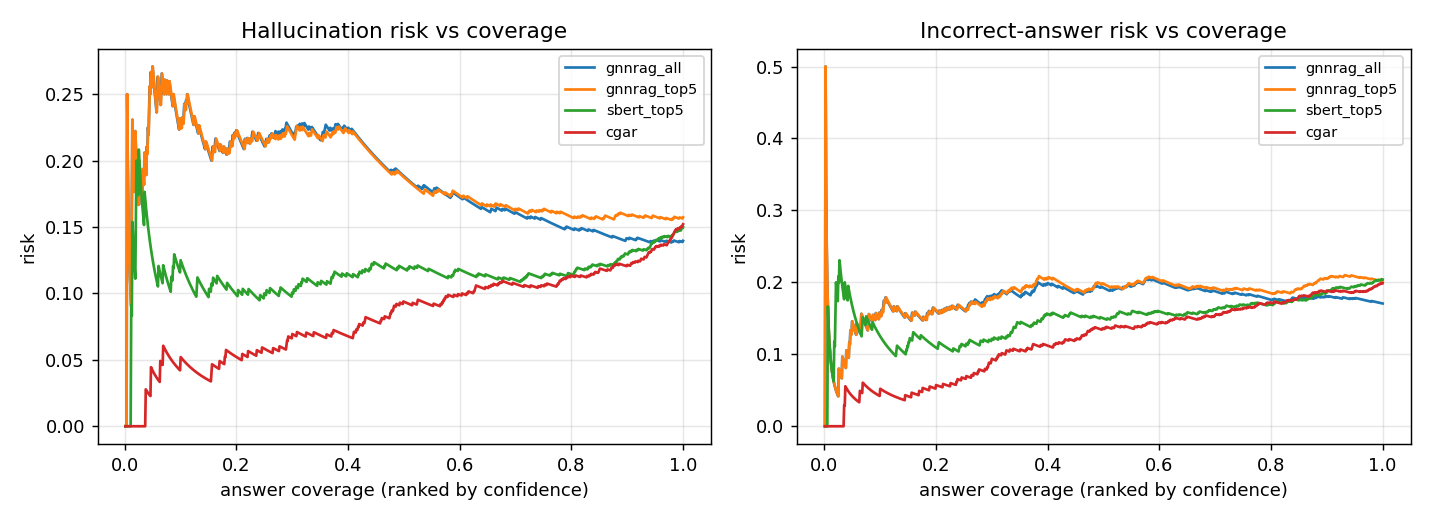

CGAR + risk gate @50%: halluc 0.094 vs all @100% 0.140 | incorrect 0.135 vs 0.171

##### ('Mistral-7B-Instruct-v0.3', 'chat')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.277,0.177,0.227,0.146,0.294,0.194,0.285,0.187,0.316,0.190
gnnrag_top5,0.280,0.187,0.226,0.146,0.299,0.205,0.294,0.200,0.302,0.214
sbert_top5,0.232,0.148,0.181,0.106,0.212,0.139,0.270,0.186,0.309,0.204
cgar,0.216,0.133,0.146,0.091,0.222,0.145,0.294,0.169,0.327,0.196


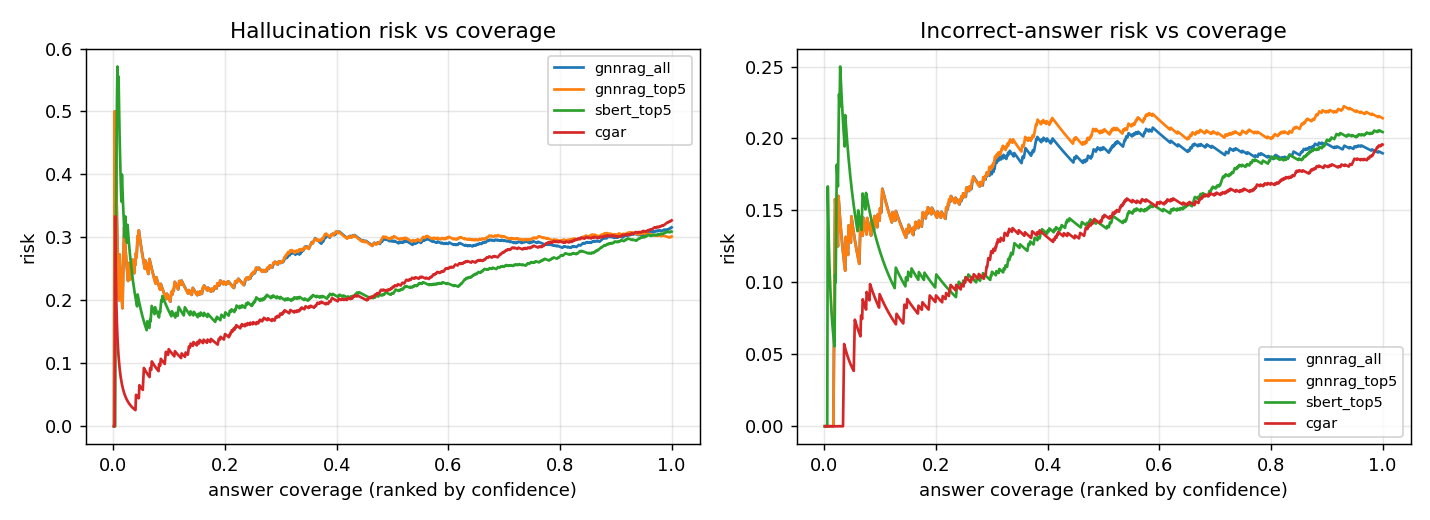

CGAR + risk gate @50%: halluc 0.222 vs all @100% 0.316 | incorrect 0.145 vs 0.190

##### ('Qwen2.5-7B-Instruct', 'chat')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.136,0.157,0.148,0.137,0.138,0.171,0.115,0.165,0.114,0.164
gnnrag_top5,0.144,0.160,0.148,0.137,0.147,0.171,0.130,0.163,0.131,0.178
sbert_top5,0.089,0.136,0.077,0.109,0.090,0.133,0.100,0.157,0.118,0.177
cgar,0.082,0.105,0.066,0.061,0.080,0.122,0.102,0.137,0.120,0.165


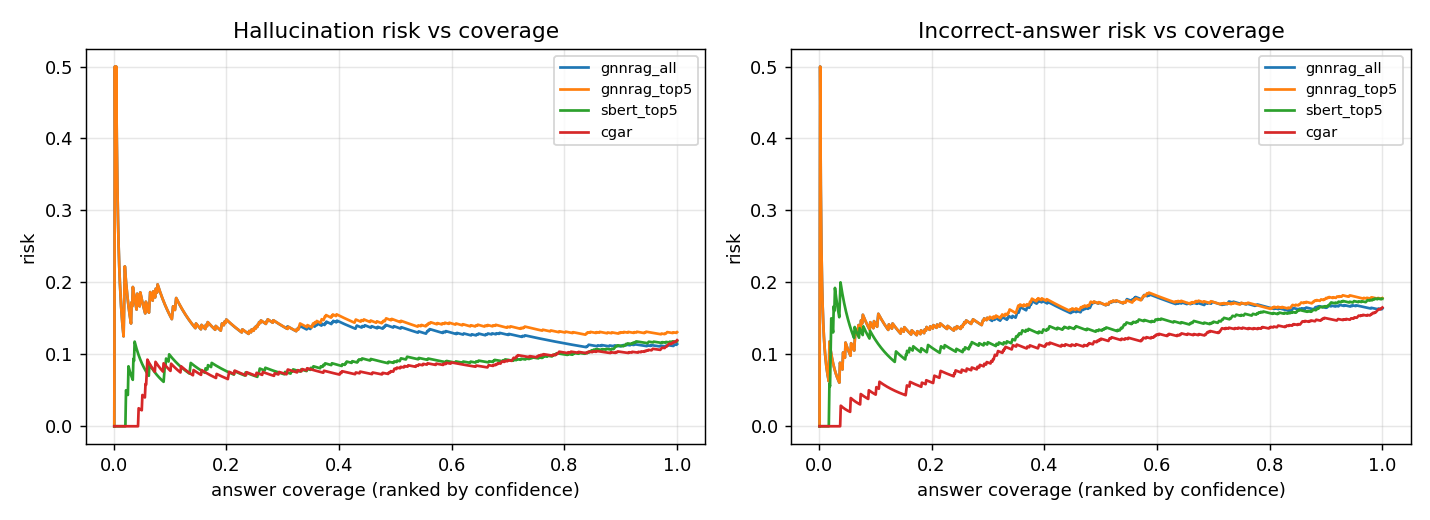

CGAR + risk gate @50%: halluc 0.080 vs all @100% 0.114 | incorrect 0.122 vs 0.164

##### ('Meta-Llama-3.1-8B-Instruct', 'cand+verify')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.0,0.190,0.0,0.196,0.0,0.185,0.0,0.183,0.001,0.176
gnnrag_top5,0.0,0.198,0.0,0.196,0.0,0.194,0.0,0.193,0.001,0.205
sbert_top5,0.0,0.155,0.0,0.113,0.0,0.150,0.0,0.175,0.001,0.209
cgar,0.0,0.105,0.0,0.062,0.0,0.107,0.0,0.151,0.001,0.192
cgar_esc,0.0,0.101,0.0,0.062,0.0,0.105,0.0,0.141,0.001,0.176


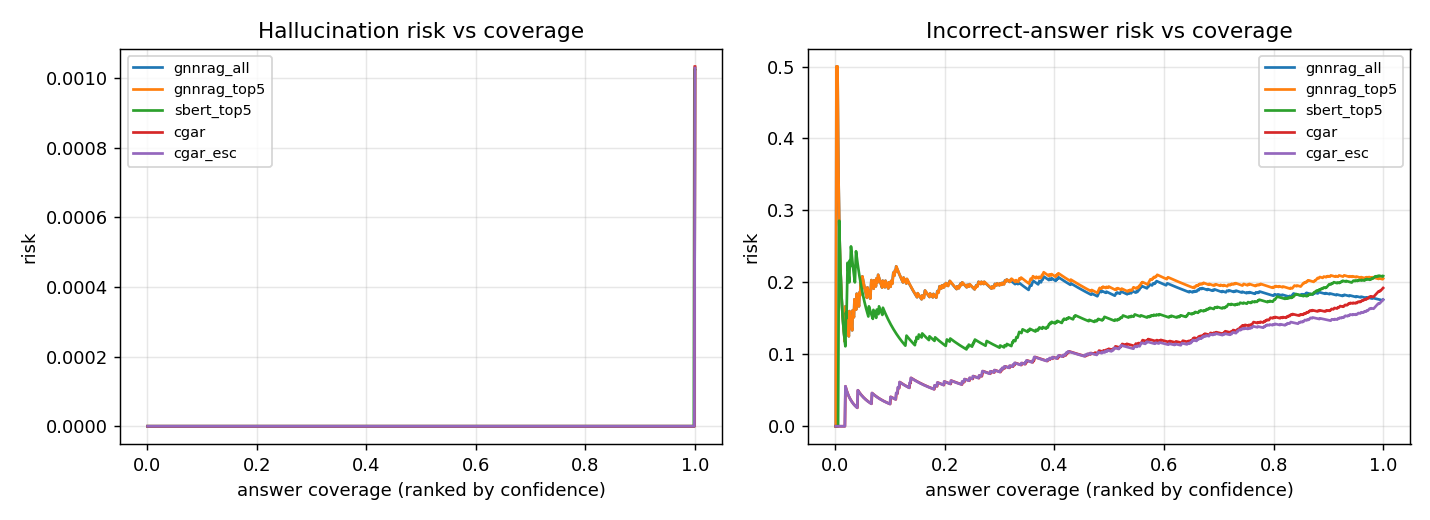

CGAR + risk gate @50%: halluc 0.000 vs all @100% 0.001 | incorrect 0.107 vs 0.176

##### ('Qwen2.5-7B-Instruct', 'cand+verify')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.0,0.210,0.0,0.196,0.0,0.217,0.0,0.211,0.002,0.209
gnnrag_top5,0.0,0.217,0.0,0.196,0.0,0.219,0.0,0.220,0.001,0.234
sbert_top5,0.0,0.165,0.0,0.116,0.0,0.161,0.0,0.193,0.001,0.227
cgar,0.0,0.125,0.0,0.060,0.0,0.131,0.0,0.180,0.001,0.225
cgar_esc,0.0,0.119,0.0,0.061,0.0,0.129,0.0,0.169,0.002,0.206


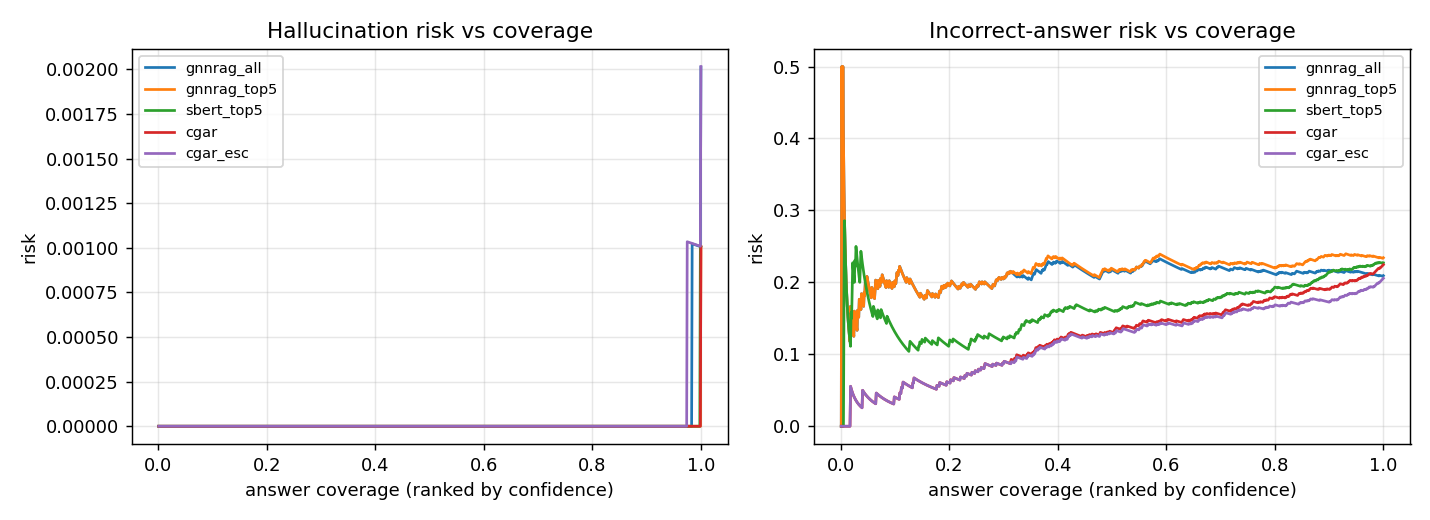

CGAR + risk gate @50%: halluc 0.000 vs all @100% 0.002 | incorrect 0.131 vs 0.209

##### ('Meta-Llama-3.1-8B-Instruct', 'lora-cand+verify')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.0,0.204,0.0,0.196,0.0,0.211,0.0,0.198,0.002,0.190
gnnrag_top5,0.0,0.216,0.0,0.196,0.0,0.219,0.0,0.218,0.001,0.229
sbert_top5,0.0,0.164,0.0,0.126,0.0,0.155,0.0,0.189,0.001,0.224
cgar,0.0,0.127,0.0,0.065,0.0,0.135,0.0,0.182,0.001,0.221
cgar_esc,0.0,0.121,0.0,0.065,0.0,0.131,0.0,0.168,0.002,0.200


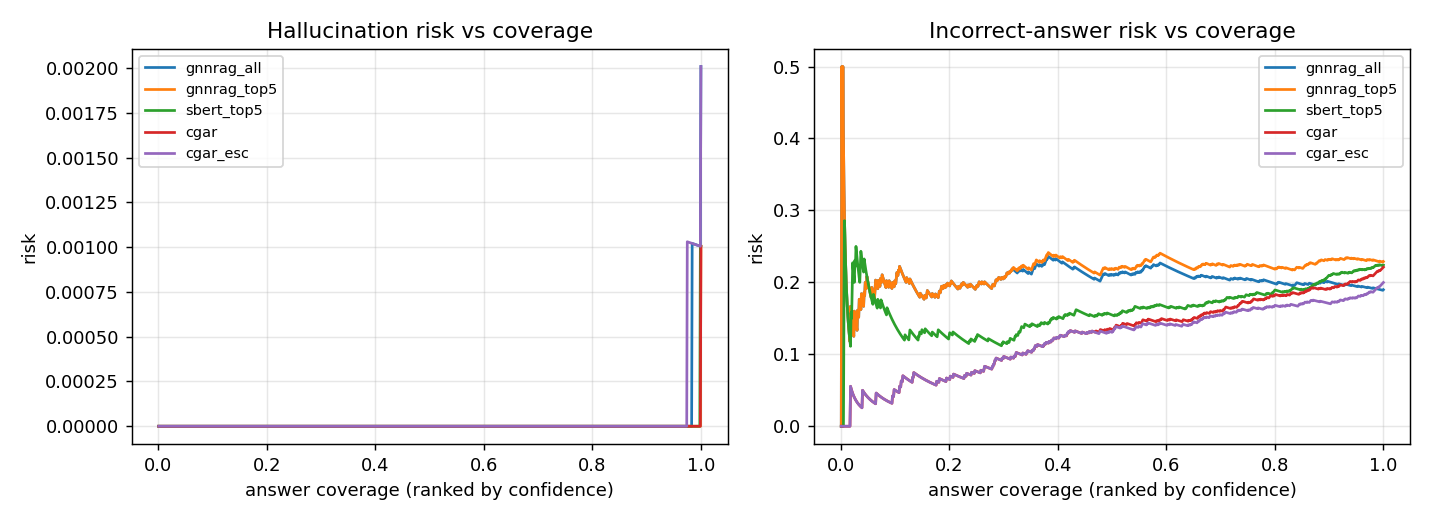

CGAR + risk gate @50%: halluc 0.000 vs all @100% 0.002 | incorrect 0.135 vs 0.190

##### ('Qwen2.5-7B-Instruct', 'lora-cand+verify')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.0,0.207,0.0,0.196,0.0,0.211,0.0,0.202,0.002,0.200
gnnrag_top5,0.0,0.220,0.0,0.196,0.0,0.223,0.0,0.222,0.001,0.234
sbert_top5,0.0,0.166,0.0,0.121,0.0,0.157,0.0,0.197,0.001,0.231
cgar,0.0,0.125,0.0,0.065,0.0,0.135,0.0,0.177,0.001,0.220
cgar_esc,0.0,0.120,0.0,0.065,0.0,0.133,0.0,0.165,0.002,0.202


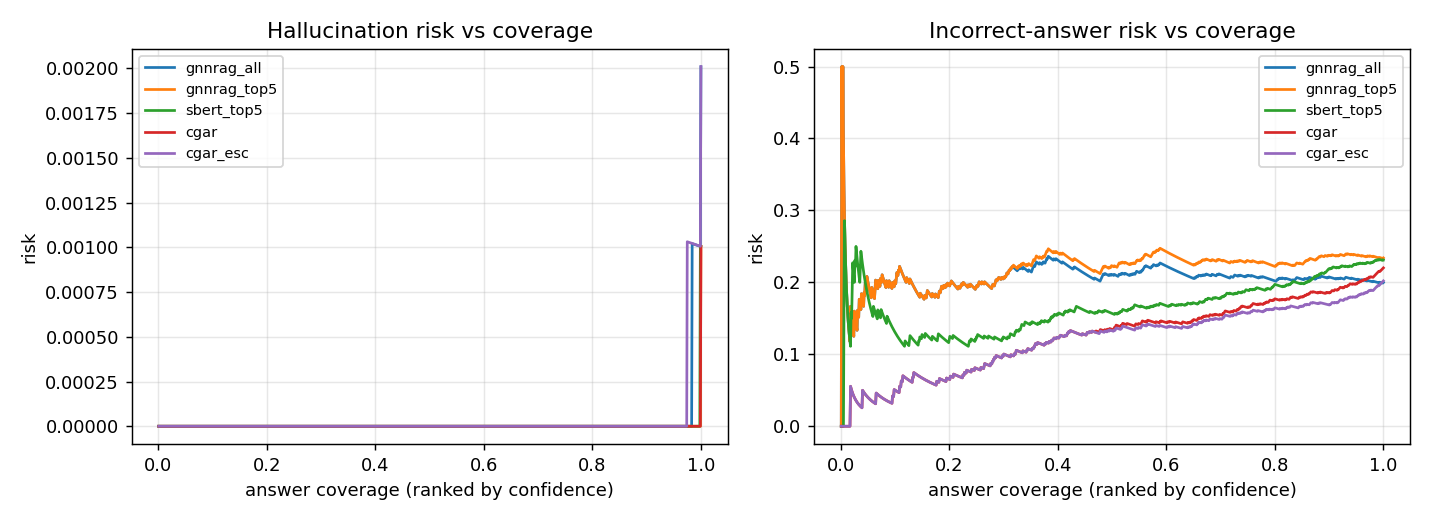

CGAR + risk gate @50%: halluc 0.000 vs all @100% 0.002 | incorrect 0.135 vs 0.200

##### ('Meta-Llama-3.1-8B-Instruct', 'grounded')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.183,0.128,0.186,0.116,0.174,0.137,0.187,0.133,0.186,0.132
gnnrag_top5,0.188,0.127,0.178,0.112,0.180,0.135,0.193,0.132,0.201,0.145
sbert_top5,0.217,0.121,0.219,0.095,0.217,0.132,0.205,0.139,0.194,0.152
cgar,0.174,0.085,0.150,0.048,0.182,0.091,0.190,0.118,0.194,0.134


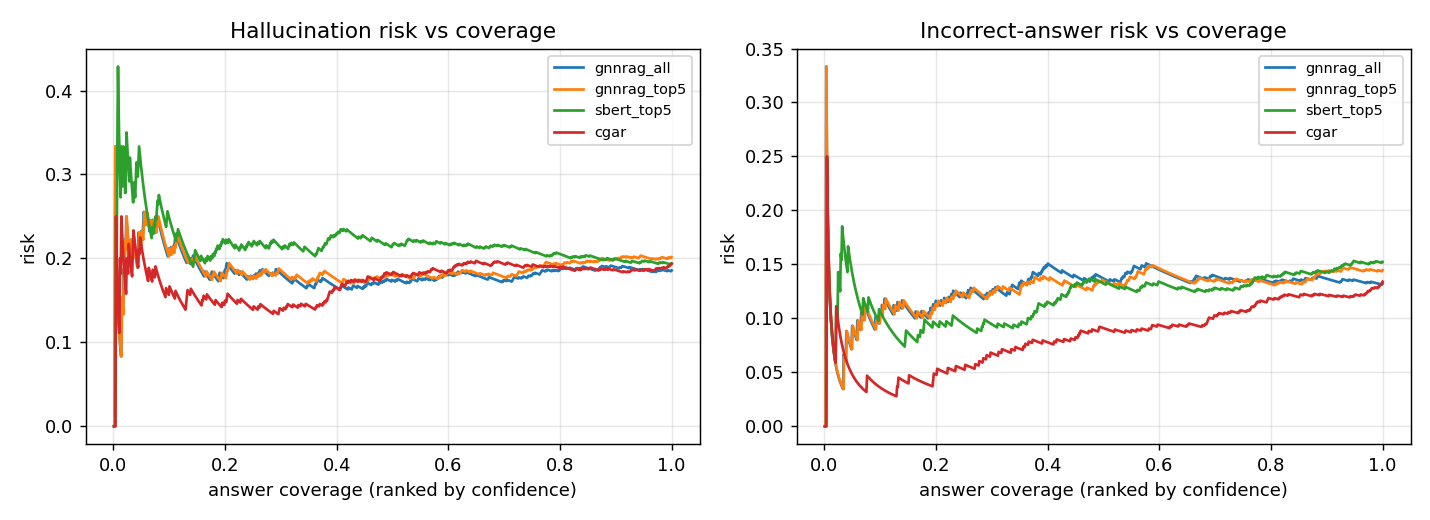

CGAR + risk gate @50%: halluc 0.182 vs all @100% 0.186 | incorrect 0.091 vs 0.132

##### ('Qwen2.5-7B-Instruct', 'grounded')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.017,0.110,0.014,0.106,0.020,0.115,0.019,0.109,0.027,0.103
gnnrag_top5,0.018,0.111,0.015,0.102,0.020,0.117,0.022,0.110,0.028,0.111
sbert_top5,0.040,0.114,0.042,0.092,0.037,0.121,0.032,0.121,0.028,0.117
cgar,0.015,0.068,0.014,0.036,0.009,0.069,0.013,0.081,0.014,0.106


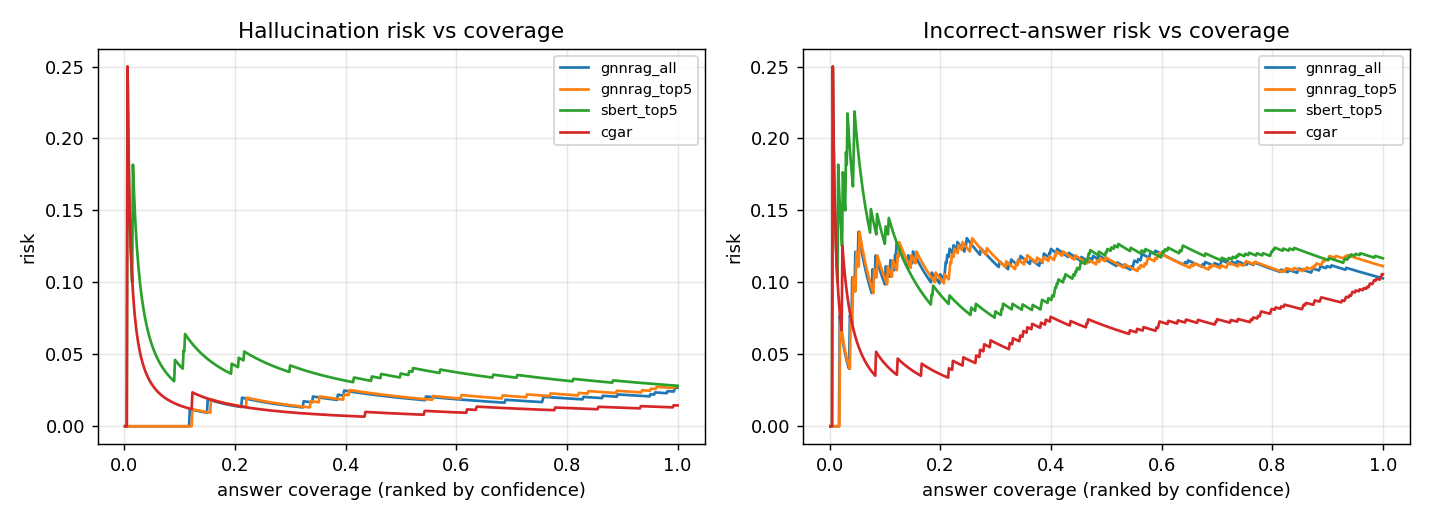

CGAR + risk gate @50%: halluc 0.009 vs all @100% 0.027 | incorrect 0.069 vs 0.103

##### ('Meta-Llama-3.1-8B-Instruct', 'chat+verify')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.0,0.197,0.0,0.197,0.0,0.202,0.0,0.189,0.002,0.178
gnnrag_top5,0.0,0.206,0.0,0.193,0.0,0.208,0.0,0.204,0.001,0.216
sbert_top5,0.0,0.158,0.0,0.120,0.0,0.158,0.0,0.173,0.001,0.211
cgar,0.0,0.106,0.0,0.042,0.0,0.121,0.0,0.163,0.001,0.202


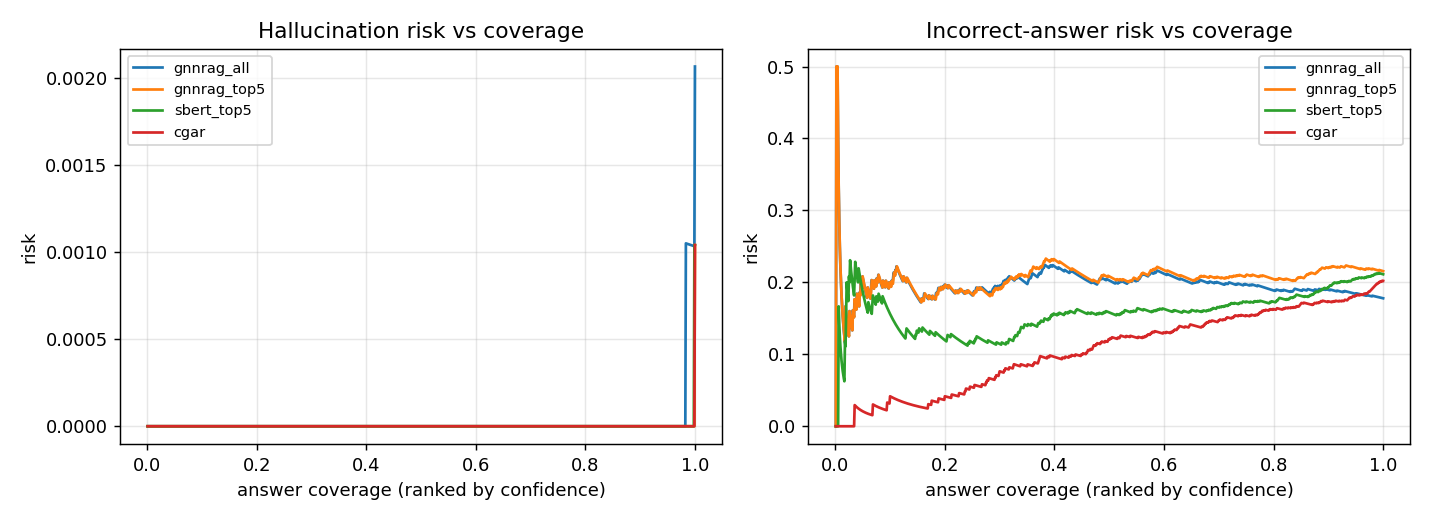

CGAR + risk gate @50%: halluc 0.000 vs all @100% 0.002 | incorrect 0.121 vs 0.178

##### ('Qwen2.5-7B-Instruct', 'chat+verify')


,aurc_halluc,aurc_incorrect,halluc@0.2,incorrect@0.2,halluc@0.5,incorrect@0.5,halluc@0.8,incorrect@0.8,halluc@1.0,incorrect@1.0
method,,,,,,,,,,
gnnrag_all,0.0,0.165,0.0,0.165,0.0,0.164,0.0,0.163,0.002,0.158
gnnrag_top5,0.0,0.171,0.0,0.165,0.0,0.169,0.0,0.169,0.001,0.179
sbert_top5,0.0,0.136,0.0,0.115,0.0,0.136,0.0,0.153,0.001,0.176
cgar,0.0,0.089,0.0,0.044,0.0,0.100,0.0,0.123,0.001,0.157


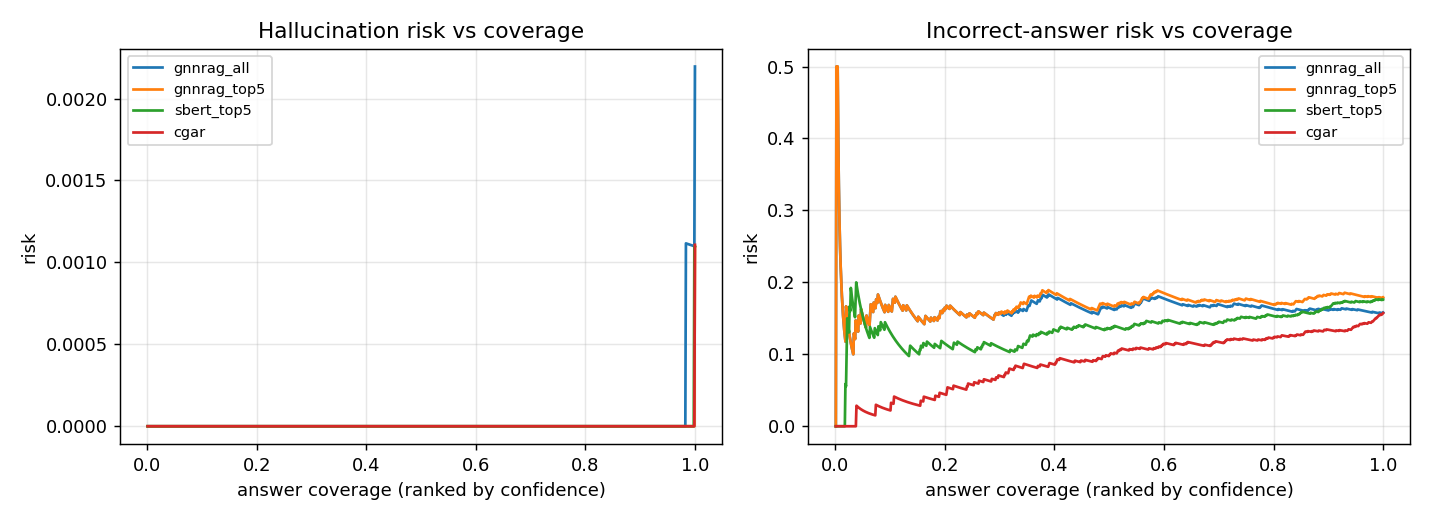

CGAR + risk gate @50%: halluc 0.000 vs all @100% 0.002 | incorrect 0.100 vs 0.158


In [7]:
for key, res in RES.items():
    dsk = list(res['datasets'])[0]; S = res['datasets'][dsk]['summaries']
    rows = []
    for m, s in S.items():
        if 'halluc_risk_at' not in s: continue
        r = dict(method=m, aurc_halluc=s['aurc_hallucination'], aurc_incorrect=s['aurc_incorrect'])
        for c in ('0.2','0.5','0.8','1.0'): r[f'halluc@{c}'] = s['halluc_risk_at'][c]; r[f'incorrect@{c}'] = s['incorrect_risk_at'][c]
        rows.append(r)
    print('\n#####', key); display(pd.DataFrame(rows).set_index('method').round(3))
    d = [x for x in READER_DIRS if tag_of(x) == key][0]
    display(Image(f'{d}/hallucination/risk_coverage_webqsp_test.png'))
    if 'cgar' in S and REF in S and 'halluc_risk_at' in S['cgar']:
        c, a = S['cgar'], S[REF]
        print(f"CGAR + risk gate @50%: halluc {c['halluc_risk_at']['0.5']:.3f} vs all @100% {a['halluc_risk_at']['1.0']:.3f} | incorrect {c['incorrect_risk_at']['0.5']:.3f} vs {a['incorrect_risk_at']['1.0']:.3f}")

## 07 - Kiểm định cặp (paired bootstrap + McNemar) trên nhãn cấp câu
Δ âm ở `hallucinated` nghĩa là ít hallucination hơn tham chiếu. `grounded_correct` và `llm_hit` để chắc rằng giảm hallucination không phải do trả lời ít đi.

In [8]:
for key, res in RES.items():
    dsk = list(res['datasets'])[0]; C = res['datasets'][dsk]['comparisons']; rows = []
    for m, byk in C.items():
        for k, c in byk.items():
            if not isinstance(c, dict) or 'bootstrap' not in c: continue
            b = c['bootstrap']
            rows.append(dict(method=m, key=k, n=c['n'], delta_pp=round(b['delta']*100, 2), ci=f"[{b['ci_low']*100:+.2f}, {b['ci_high']*100:+.2f}]",
                             p_boot=round(b['p_value'], 4), p_mcnemar=round(c['mcnemar']['p_value'], 4), sig=c['significant_0.05']))
    print('\n#####', key, '| A − ' + REF); display(pd.DataFrame(rows))
    for m, byk in C.items(): print(m, 'bất đồng hallucinated (a=method, b=ref):', byk.get('disagreement_hallucinated'))


##### ('Meta-Llama-3.1-8B-Instruct', 'chat') | A − gnnrag_all


,method,key,n,delta_pp,ci,p_boot,p_mcnemar,sig
0,gnnrag_top5,hallucinated,996,1.61,"[+0.20, +3.01]",0.0334,0.0402,True
1,gnnrag_top5,grounded_correct,996,-4.02,"[-5.62, -2.51]",0.0000,0.0000,True
2,gnnrag_top5,llm_hit,996,-3.61,"[-5.22, -2.21]",0.0000,0.0000,True
3,sbert_top5,hallucinated,996,0.90,"[-0.70, +2.51]",0.2908,0.3135,False
4,sbert_top5,grounded_correct,996,-4.02,"[-5.72, -2.31]",0.0000,0.0000,True
5,sbert_top5,llm_hit,996,-3.71,"[-5.42, -2.01]",0.0000,0.0000,True
6,cgar,hallucinated,996,1.10,"[-0.70, +2.91]",0.2484,0.2664,False
7,cgar,grounded_correct,996,-3.11,"[-4.82, -1.50]",0.0004,0.0004,True
8,cgar,llm_hit,996,-3.31,"[-5.02, -1.71]",0.0000,0.0001,True


gnnrag_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 826, 'a1_b1': 116, 'a1_b0': 35, 'a0_b1': 19}
sbert_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 825, 'a1_b1': 108, 'a1_b0': 36, 'a0_b1': 27}
cgar bất đồng hallucinated (a=method, b=ref): {'a0_b0': 815, 'a1_b1': 100, 'a1_b0': 46, 'a0_b1': 35}

##### ('Mistral-7B-Instruct-v0.3', 'chat') | A − gnnrag_all


,method,key,n,delta_pp,ci,p_boot,p_mcnemar,sig
0,gnnrag_top5,hallucinated,996,-1.31,"[-3.41, +0.80]",0.2316,0.2503,False
1,gnnrag_top5,grounded_correct,996,0.40,"[-1.51, +2.41]",0.7240,0.7644,False
2,gnnrag_top5,llm_hit,996,-2.11,"[-3.82, -0.50]",0.0110,0.0170,True
3,sbert_top5,hallucinated,996,-0.60,"[-3.01, +1.91]",0.6512,0.6891,False
4,sbert_top5,grounded_correct,996,-0.30,"[-2.71, +2.11]",0.8426,0.8663,False
5,sbert_top5,llm_hit,996,-1.31,"[-3.01, +0.40]",0.1484,0.1597,False
6,cgar,hallucinated,996,1.10,"[-1.51, +3.71]",0.4338,0.4549,False
7,cgar,grounded_correct,996,-0.50,"[-3.01, +2.01]",0.7222,0.7527,False
8,cgar,llm_hit,996,-0.60,"[-2.31, +1.10]",0.5326,0.5716,False


gnnrag_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 635, 'a1_b1': 252, 'a1_b0': 48, 'a0_b1': 61}
sbert_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 608, 'a1_b1': 232, 'a1_b0': 75, 'a0_b1': 81}
cgar bất đồng hallucinated (a=method, b=ref): {'a0_b0': 588, 'a1_b1': 229, 'a1_b0': 95, 'a0_b1': 84}

##### ('Qwen2.5-7B-Instruct', 'chat') | A − gnnrag_all


,method,key,n,delta_pp,ci,p_boot,p_mcnemar,sig
0,gnnrag_top5,hallucinated,996,1.51,"[+0.20, +2.81]",0.0254,0.0315,True
1,gnnrag_top5,grounded_correct,996,-2.51,"[-3.92, -1.10]",0.0014,0.0006,True
2,gnnrag_top5,llm_hit,996,-1.41,"[-2.81, -0.10]",0.0408,0.0541,True
3,sbert_top5,hallucinated,996,0.40,"[-1.10, +1.91]",0.6654,0.7035,False
4,sbert_top5,grounded_correct,996,-1.31,"[-3.01, +0.30]",0.1442,0.1597,False
5,sbert_top5,llm_hit,996,-1.00,"[-2.51, +0.50]",0.2052,0.2370,False
6,cgar,hallucinated,996,0.40,"[-1.20, +2.01]",0.6718,0.7080,False
7,cgar,grounded_correct,996,-0.80,"[-2.41, +0.80]",0.3538,0.3817,False
8,cgar,llm_hit,996,-0.80,"[-2.31, +0.70]",0.3086,0.3497,False


... (13 outputs left out)

,method,key,n,delta_pp,ci,p_boot,p_mcnemar,sig
0,gnnrag_top5,hallucinated,996,-0.10,"[-0.30, +0.00]",0.7372,1.0000,False
1,gnnrag_top5,grounded_correct,996,-4.12,"[-5.52, -2.81]",0.0000,0.0000,True
2,gnnrag_top5,llm_hit,996,-4.22,"[-5.62, -2.91]",0.0000,0.0000,True
3,sbert_top5,hallucinated,996,-0.10,"[-0.30, +0.00]",0.7372,1.0000,False
4,sbert_top5,grounded_correct,996,-3.61,"[-5.12, -2.11]",0.0000,0.0000,True
5,sbert_top5,llm_hit,996,-3.71,"[-5.22, -2.21]",0.0000,0.0000,True
6,cgar,hallucinated,996,-0.10,"[-0.30, +0.00]",0.7372,1.0000,False
7,cgar,grounded_correct,996,-2.81,"[-4.22, -1.41]",0.0000,0.0001,True
8,cgar,llm_hit,996,-2.91,"[-4.32, -1.61]",0.0000,0.0000,True


gnnrag_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 994, 'a0_b1': 1, 'a1_b1': 1}
sbert_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 994, 'a0_b1': 1, 'a1_b1': 1}
cgar bất đồng hallucinated (a=method, b=ref): {'a0_b0': 994, 'a0_b1': 1, 'a1_b1': 1}

##### ('Qwen2.5-7B-Instruct', 'chat+verify') | A − gnnrag_all


,method,key,n,delta_pp,ci,p_boot,p_mcnemar,sig
0,gnnrag_top5,hallucinated,996,-0.10,"[-0.30, +0.00]",0.7372,1.0000,False
1,gnnrag_top5,grounded_correct,996,-1.91,"[-3.21, -0.70]",0.0052,0.0054,True
2,gnnrag_top5,llm_hit,996,-2.01,"[-3.31, -0.80]",0.0032,0.0029,True
3,sbert_top5,hallucinated,996,-0.10,"[-0.30, +0.00]",0.7372,1.0000,False
4,sbert_top5,grounded_correct,996,-1.31,"[-2.71, +0.10]",0.0702,0.0919,False
5,sbert_top5,llm_hit,996,-1.41,"[-2.81, +0.00]",0.0502,0.0649,False
6,cgar,hallucinated,996,-0.10,"[-0.30, +0.00]",0.7372,1.0000,False
7,cgar,grounded_correct,996,-0.50,"[-1.81, +0.80]",0.4788,0.5424,False
8,cgar,llm_hit,996,-0.60,"[-1.91, +0.60]",0.3820,0.4408,False


gnnrag_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 994, 'a0_b1': 1, 'a1_b1': 1}
sbert_top5 bất đồng hallucinated (a=method, b=ref): {'a0_b0': 994, 'a0_b1': 1, 'a1_b1': 1}
cgar bất đồng hallucinated (a=method, b=ref): {'a0_b0': 994, 'a0_b1': 1, 'a1_b1': 1}


## 08 - Prompt gốc vs prompt grounded (D1)
Cùng reader, cùng 1000 qid. Kỳ vọng: grounded giảm claim-HR và tăng abstention; cần xem `grounded_correct_rate` có giảm theo không.

In [9]:
readers = sorted({k[0] for k in RES})
for rd in readers:
    if (rd, 'chat') in RES and (rd, 'grounded') in RES:
        a, g = summ(RES[(rd, 'chat')]), summ(RES[(rd, 'grounded')])
        cols = ['answer_coverage','abstention_rate','claim_hallucination_rate','question_hallucination_rate','llm_hit','grounded_correct_rate','grounded_answer_f1']
        cmp = pd.concat({'chat': a[cols].astype(float), 'grounded': g[cols].astype(float)}, axis=1).round(3)
        print('\n#####', rd); display(cmp)
        for m in ('gnnrag_all', 'cgar'):
            if m in a.index and m in g.index:
                print(f"  {m}: QHR {a.loc[m,'question_hallucination_rate']:.3f} -> {g.loc[m,'question_hallucination_rate']:.3f} | grounded_correct {a.loc[m,'grounded_correct_rate']:.3f} -> {g.loc[m,'grounded_correct_rate']:.3f} | abstain {a.loc[m,'abstention_rate']:.3f} -> {g.loc[m,'abstention_rate']:.3f}")
    else:
        print(rd, ': chỉ có một prompt -> bỏ qua so sánh')


##### Meta-Llama-3.1-8B-Instruct


chat                                           \
            answer_coverage abstention_rate claim_hallucination_rate   
gnnrag_all            0.971           0.018                    0.076   
gnnrag_top5           0.964           0.020                    0.159   
sbert_top5            0.965           0.025                    0.130   
cgar                  0.964           0.025                    0.132   

                                                                       \
            question_hallucination_rate llm_hit grounded_correct_rate   
gnnrag_all                        0.140   0.805                 0.744   
gnnrag_top5                       0.157   0.769                 0.704   
sbert_top5                        0.150   0.768                 0.704   
cgar                              0.152   0.772                 0.713   

                                      grounded                  \
            grounded_answer_f1 answer_coverage abstention_rate   
gnnrag_all               0.612           0.865           0.135   
gnnrag_top5              0.555           0.847           0.153   
sbert_top5               0.556           0.850           0.150   
cgar                     0.573           0.839           0.161   

                                                                          \
            claim_hallucination_rate question_hallucination_rate llm_hit   
gnnrag_all                     0.078                       0.186   0.751   
gnnrag_top5                    0.113                       0.201   0.725   
sbert_top5                     0.096                       0.194   0.721   
cgar                           0.092                       0.194   0.727   

                                                      
            grounded_correct_rate grounded_answer_f1  
gnnrag_all                  0.629              0.581  
gnnrag_top5                 0.596              0.527  
sbert_top5                  0.594              0.526  
cgar                        0.593              0.535

  gnnrag_all: QHR 0.140 -> 0.186 | grounded_correct 0.744 -> 0.629 | abstain 0.018 -> 0.135
  cgar: QHR 0.152 -> 0.194 | grounded_correct 0.713 -> 0.593 | abstain 0.025 -> 0.161
Mistral-7B-Instruct-v0.3 : chỉ có một prompt -> bỏ qua so sánh

##### Qwen2.5-7B-Instruct


chat                                           \
            answer_coverage abstention_rate claim_hallucination_rate   
gnnrag_all            0.915           0.027                    0.053   
gnnrag_top5           0.914           0.020                    0.100   
sbert_top5            0.918           0.018                    0.081   
cgar                  0.907           0.025                    0.085   

                                                                       \
            question_hallucination_rate llm_hit grounded_correct_rate   
gnnrag_all                        0.114   0.765                 0.722   
gnnrag_top5                       0.131   0.751                 0.697   
sbert_top5                        0.118   0.755                 0.709   
cgar                              0.120   0.757                 0.714   

                                      grounded                  \
            grounded_answer_f1 answer_coverage abstention_rate   
gnnrag_all               0.609           0.713           0.287   
gnnrag_top5              0.555           0.686           0.314   
sbert_top5               0.561           0.714           0.286   
cgar                     0.566           0.694           0.306   

                                                                          \
            claim_hallucination_rate question_hallucination_rate llm_hit   
gnnrag_all                     0.017                       0.027   0.640   
gnnrag_top5                    0.016                       0.028   0.609   
sbert_top5                     0.015                       0.028   0.631   
cgar                           0.007                       0.014   0.620   

                                                      
            grounded_correct_rate grounded_answer_f1  
gnnrag_all                  0.630              0.528  
gnnrag_top5                 0.602              0.478  
sbert_top5                  0.620              0.486  
cgar                        0.617              0.490

  gnnrag_all: QHR 0.114 -> 0.027 | grounded_correct 0.722 -> 0.630 | abstain 0.027 -> 0.287
  cgar: QHR 0.120 -> 0.014 | grounded_correct 0.714 -> 0.617 | abstain 0.025 -> 0.306


## 09 - Escalation theo confidence ở mức hallucination
Chính sách hai tầng: CGAR nếu confidence >= τ, ngược lại dùng toàn bộ path của GNN-RAG-all. Tính trên verdict của hai method (cùng qid): QHR, grounded_correct, llm_hit và cost theo τ. Cho biết abstain/escalate có giảm hallucination mà không mất correctness không.

In [10]:
def halluc_escalation(key, a='cgar', b='gnnrag_all'):
    A = {v['qid']: v for v in CL[(key, a)]}; B = {v['qid']: v for v in CL[(key, b)]}
    q = [x for x in sorted(set(A) & set(B)) if A[x].get('confidence') is not None]
    conf = np.array([A[x]['confidence'] for x in q]); taus = [-np.inf] + list(np.quantile(conf, np.linspace(0.1, 0.9, 9))) + [np.inf]
    rows = []
    for t in taus:
        use_b = conf < t; mixed = [B[x] if u else A[x] for x, u in zip(q, use_b)]
        rows.append(dict(tau=('-inf' if t == -np.inf else '+inf' if t == np.inf else round(float(t), 3)), escalated=float(use_b.mean()),
                         cost=np.mean([v['cost'] for v in mixed]), QHR=np.mean([v['hallucinated'] for v in mixed if v['answered']]),
                         grounded_correct=np.mean([v['grounded_correct'] for v in mixed]), llm_hit=np.mean([v['llm_hit'] for v in mixed])))
    return pd.DataFrame(rows)
for key in RES:
    if (key, 'cgar') in CL and (key, 'gnnrag_all') in CL:
        print('\n#####', key); display(halluc_escalation(key).round(4))


##### ('Meta-Llama-3.1-8B-Instruct', 'chat')


,tau,escalated,cost,QHR,grounded_correct,llm_hit
0,-inf,0.0000,3.4618,0.1521,0.7129,0.7721
1,0.145,0.1004,4.6847,0.1452,0.7189,0.7771
2,0.307,0.1998,6.2129,0.1473,0.7239,0.7811
3,0.515,0.3002,7.1546,0.1402,0.7390,0.7962
4,0.672,0.3996,7.7058,0.1421,0.7390,0.7972
5,0.87,0.5000,7.9217,0.1378,0.7430,0.8002
6,0.965,0.5994,8.1486,0.1347,0.7450,0.8022
7,0.986,0.6998,8.2972,0.1386,0.7450,0.8062
8,0.994,0.7992,8.4036,0.1358,0.7460,0.8062
9,0.998,0.8996,8.4759,0.1386,0.7450,0.8052



##### ('Mistral-7B-Instruct-v0.3', 'chat')


,tau,escalated,cost,QHR,grounded_correct,llm_hit
0,-inf,0.0000,3.4618,0.3269,0.6114,0.8002
1,0.145,0.1004,4.6847,0.3340,0.6034,0.8012
2,0.307,0.1998,6.2129,0.3397,0.6014,0.8102
3,0.515,0.3002,7.1546,0.3306,0.6084,0.8122
4,0.672,0.3996,7.7058,0.3263,0.6104,0.8082
5,0.87,0.5000,7.9217,0.3283,0.6074,0.8062
6,0.965,0.5994,8.1486,0.3256,0.6135,0.8102
7,0.986,0.6998,8.2972,0.3256,0.6135,0.8072
8,0.994,0.7992,8.4036,0.3216,0.6135,0.8062
9,0.998,0.8996,8.4759,0.3148,0.6175,0.8072



##### ('Qwen2.5-7B-Instruct', 'chat')


,tau,escalated,cost,QHR,grounded_correct,llm_hit
0,-inf,0.0000,3.4618,0.1196,0.7139,0.7570
1,0.145,0.1004,4.6847,0.1204,0.7129,0.7590
2,0.307,0.1998,6.2129,0.1251,0.7078,0.7550
3,0.515,0.3002,7.1546,0.1261,0.7098,0.7580
4,0.672,0.3996,7.7058,0.1264,0.7129,0.7631
5,0.87,0.5000,7.9217,0.1273,0.7149,0.7641
6,0.965,0.5994,8.1486,0.1242,0.7159,0.7631
7,0.986,0.6998,8.2972,0.1207,0.7199,0.7661
8,0.994,0.7992,8.4036,0.1153,0.7209,0.7651
9,0.998,0.8996,8.4759,0.1140,0.7229,0.7661


... (12 outputs left out)


##### ('Meta-Llama-3.1-8B-Instruct', 'chat+verify')


,tau,escalated,cost,QHR,grounded_correct,llm_hit
0,-inf,0.0000,3.4618,0.0010,0.7681,0.7691
1,0.145,0.1004,4.6847,0.0021,0.7731,0.7751
2,0.307,0.1998,6.2129,0.0021,0.7781,0.7801
3,0.515,0.3002,7.1546,0.0021,0.7922,0.7942
4,0.672,0.3996,7.7058,0.0021,0.7952,0.7972
5,0.87,0.5000,7.9217,0.0021,0.7952,0.7972
6,0.965,0.5994,8.1486,0.0021,0.7962,0.7982
7,0.986,0.6998,8.2972,0.0021,0.7972,0.7992
8,0.994,0.7992,8.4036,0.0021,0.7962,0.7982
9,0.998,0.8996,8.4759,0.0021,0.7962,0.7982



##### ('Qwen2.5-7B-Instruct', 'chat+verify')


,tau,escalated,cost,QHR,grounded_correct,llm_hit
0,-inf,0.0000,3.4618,0.0011,0.7641,0.7641
1,0.145,0.1004,4.6847,0.0022,0.7631,0.7641
2,0.307,0.1998,6.2129,0.0022,0.7610,0.7620
3,0.515,0.3002,7.1546,0.0022,0.7651,0.7661
4,0.672,0.3996,7.7058,0.0022,0.7661,0.7671
5,0.87,0.5000,7.9217,0.0022,0.7681,0.7691
6,0.965,0.5994,8.1486,0.0022,0.7681,0.7691
7,0.986,0.6998,8.2972,0.0022,0.7701,0.7711
8,0.994,0.7992,8.4036,0.0022,0.7691,0.7701
9,0.998,0.8996,8.4759,0.0022,0.7701,0.7711


## 10 - (Tuỳ chọn, GPU) LLM judge cho claim UNCERTAIN
Judge chỉ xử lý claim UNCERTAIN và `in_context_no_proof`; trả về SUPPORTED / CONTRADICTED / UNCERTAIN. Đặt `JUDGE = 'hf:<model>'` ở cell 01. Không dùng một judge làm ground truth; dùng để thu hẹp vùng UNCERTAIN rồi đối chiếu với human review ở cell 11.

In [11]:
if JUDGE:
    d = READER_DIRS[0]; key = tag_of(d)
    RESJ = H.run(d, [WEBQSP_TE], methods=METHODS, ref=REF, judge_spec=JUDGE, strict=STRICT, review_n=0, n_bootstrap=2000,
                 out_dir=f'{d}/hallucination_judge', verbose=False)
    base, judged = summ(RES[key]), summ(RESJ)
    cols = ['claim_hallucination_rate','question_hallucination_rate','uncertain_rate','contradiction_rate','grounded_correct_rate']
    display(pd.concat({'no_judge': base[cols].astype(float), 'judge': judged[cols].astype(float)}, axis=1).round(3))
else:
    print('[skip] JUDGE = None')

[skip] JUDGE = None


## 11 - Human review: xuất mẫu, nạp nhãn, đo detector
`review_sample_webqsp_test.csv` (cell 02) có cột `human_hallucinated` (0/1) và `human_label_per_claim` để người gán nhãn điền; nếu hai người gán, lưu hai file `..._A.csv`, `..._B.csv`. Cell này đo precision / recall / F1 của detector so với người và Cohen's kappa giữa hai người. Chỉ khi detector đạt mức chấp nhận được (ví dụ F1 >= 0.8) mới dùng số ở cell 02 để viết claim.

In [12]:
def load_review(path):
    df = pd.read_csv(path); df = df[df['human_hallucinated'].astype(str).str.strip().isin(['0','1'])]
    df['human_hallucinated'] = df['human_hallucinated'].astype(int); return df
def detector_scores(df):
    y, p = df['human_hallucinated'].values, df['auto_hallucinated'].astype(int).values
    tp = int(((y == 1) & (p == 1)).sum()); fp = int(((y == 0) & (p == 1)).sum()); fn = int(((y == 1) & (p == 0)).sum()); tn = int(((y == 0) & (p == 0)).sum())
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1); f1 = 2 * prec * rec / max(prec + rec, 1e-9)
    return dict(n=len(df), tp=tp, fp=fp, fn=fn, tn=tn, precision=round(prec, 3), recall=round(rec, 3), f1=round(f1, 3), acc=round((tp + tn) / max(len(df), 1), 3))
def cohen_kappa(a, b):
    a, b = np.asarray(a), np.asarray(b); po = (a == b).mean()
    pe = sum(((a == k).mean()) * ((b == k).mean()) for k in set(a) | set(b)); return (po - pe) / max(1 - pe, 1e-9)
for d in READER_DIRS:
    base = f'{d}/hallucination/review_sample_webqsp_test'
    files = [p for p in (base + '.csv', base + '_A.csv', base + '_B.csv') if os.path.exists(p)]
    filled = []
    for p in files:
        df = load_review(p)
        if len(df): filled.append((p, df)); print(os.path.basename(d), os.path.basename(p), 'nhãn người:', len(df), '| detector:', detector_scores(df))
    if len(filled) >= 2:
        A, B = filled[-2][1].set_index(['qid','method']), filled[-1][1].set_index(['qid','method']); common = A.index.intersection(B.index)
        print('  Cohen kappa giữa hai người gán nhãn (n=%d): %.3f' % (len(common), cohen_kappa(A.loc[common,'human_hallucinated'], B.loc[common,'human_hallucinated'])))
    if not filled: print(os.path.basename(d), ': chưa có nhãn người trong', os.path.basename(base) + '.csv')

b08_reader_Meta-Llama-3.1-8B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08_reader_Mistral-7B-Instruct-v0.3 : chưa có nhãn người trong review_sample_webqsp_test.csv
b08_reader_Qwen2.5-7B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08c_reader_Meta-Llama-3.1-8B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08c_reader_Qwen2.5-7B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08f_reader_Meta-Llama-3.1-8B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08f_reader_Qwen2.5-7B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08g_reader_Meta-Llama-3.1-8B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08g_reader_Qwen2.5-7B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08v_reader_Meta-Llama-3.1-8B-Instruct : chưa có nhãn người trong review_sample_webqsp_test.csv
b08v_reader_Qwen2.5-7B-Instruct : chưa có nhãn người trong review_sample_

## 12 - Tổng kết: claim nào đứng được
Checklist tự động từ các bảng trên. Mỗi claim chỉ được viết vào báo cáo kèm Δ, CI, p của cell 07 và kết quả kiểm định detector ở cell 11.

In [3]:
# runtime mới, chưa chạy cell 02: nạp kết quả verifier đã lưu trên Drive (<reader_dir>/hallucination/hallucination.json), không chạy lại ~35 phút
if 'RES' not in globals() or not RES:
    RES = {}
    for d in READER_DIRS:
        try:
            with open(f'{d}/hallucination/hallucination.json') as f: RES[tag_of(d)] = json.load(f)
        except FileNotFoundError: print('[skip] chưa có', f'{d}/hallucination/hallucination.json', '-> chạy cell 02 cho thư mục này')
    print('nạp', len(RES), 'cấu hình từ Drive')
def gate(cond, msg): print(('PASS  ' if cond else 'FAIL  ') + msg)
lines = []
for key, res in RES.items():
    dsk = list(res['datasets'])[0]; S = res['datasets'][dsk]['summaries']; C = res['datasets'][dsk]['comparisons']
    if REF not in S: continue
    verified = key[1].endswith('verify')
    for M in [m for m in ('cgar', 'cgar_esc') if m in S]:
        c = C.get(M, {}).get('hallucinated', {}).get('bootstrap', {}); g = C.get(M, {}).get('grounded_correct', {}).get('bootstrap', {})
        print('\n#####', key, '|', M)
        gate(bool(c) and (c['delta'] <= 0 or c['p_value'] >= 0.05), f"{M} không tăng question-HR so với {REF} (Δ={c.get('delta', 0)*100:+.2f} pp, p={c.get('p_value', 1):.3f})")
        gate(bool(g) and (g['delta'] >= 0 or g['p_value'] >= 0.05), f"{M} không giảm grounded-correct so với {REF} (Δ={g.get('delta', 0)*100:+.2f} pp, p={g.get('p_value', 1):.3f})")
        if verified:
            # QHR ~ 0 theo cấu trúc (grounding dùng cùng luật với verifier): AURC-halluc và risk gate không còn ý nghĩa,
            # thay bằng strict QHR (đếm cả UNCERTAIN = endpoint sai quan hệ) là chỉ số bịa còn lại
            qs, qr = S[M].get('question_hallucination_rate_strict', 1), S[REF].get('question_hallucination_rate_strict', 1)
            gate(qs <= qr + 0.01, f"{M} strict-QHR (kể cả UNCERTAIN) không cao hơn {REF} quá 1 pp ({qs:.3f} vs {qr:.3f})")
            gate(S[M].get('aurc_incorrect', 1) < S[REF].get('aurc_incorrect', 1), f"AURC-incorrect {M} {S[M].get('aurc_incorrect'):.3f} < {REF} {S[REF].get('aurc_incorrect'):.3f}")
        else:
            gate('aurc_hallucination' in S[M] and S[M]['aurc_hallucination'] < S[REF].get('aurc_hallucination', 1), f"AURC-hallucination {M} {S[M].get('aurc_hallucination'):.3f} < {REF} {S[REF].get('aurc_hallucination'):.3f}")
            gate(S[M]['halluc_risk_at']['0.5'] < S[REF]['halluc_risk_at']['1.0'] if 'halluc_risk_at' in S[M] else False, f'{M} + risk gate @50% coverage hallucinate ít hơn all @100%')
        gate(S[M]['abstention_rate'] <= S[REF]['abstention_rate'] + 0.05, f'{M} không thắng nhờ abstain nhiều hơn (abstention chênh <= 5 pp)')
        lines.append(f"{key} | {M}: QHR {S[M]['question_hallucination_rate']:.3f} vs {REF} {S[REF]['question_hallucination_rate']:.3f}; strict {S[M].get('question_hallucination_rate_strict', float('nan')):.3f} vs {S[REF].get('question_hallucination_rate_strict', float('nan')):.3f}; grounded-correct {S[M]['grounded_correct_rate']:.3f} vs {S[REF]['grounded_correct_rate']:.3f}")
# CGAR-G headline: cgar_esc (cand+verify, zero-shot và LoRA) so với GNN-RAG-all prompt chat gốc, cùng reader, cùng 1000 câu
for rd in sorted({k[0] for k in RES}):
  for cfg in ('cand+verify', 'lora-cand+verify'):
    if (rd, cfg) in RES and (rd, 'chat') in RES:
        a = RES[(rd, cfg)]; b = RES[(rd, 'chat')]
        Sa = a['datasets'][list(a['datasets'])[0]]['summaries']; Sb = b['datasets'][list(b['datasets'])[0]]['summaries']
        if 'cgar_esc' in Sa and REF in Sb:
            x, y = Sa['cgar_esc'], Sb[REF]
            print(f"\n{rd}: cgar_esc({cfg}) vs all(chat): grounded-correct {x['grounded_correct_rate']:.3f} vs {y['grounded_correct_rate']:.3f} | "
                  f"QHR {x['question_hallucination_rate']:.3f} vs {y['question_hallucination_rate']:.3f} | strict {x['question_hallucination_rate_strict']:.3f} vs {y['question_hallucination_rate_strict']:.3f} | "
                  f"llm_hit {x['llm_hit']:.3f} vs {y['llm_hit']:.3f}")
summary_path = f'{RESULTS}/p9_hallucination_summary.md'
with open(summary_path, 'w') as f:
    f.write('# P9 hallucination summary\n\n' + '\n'.join('- ' + l for l in lines) + '\n\nChi tiết: <reader_dir>/hallucination/report_webqsp_test.md\n')
print('\n'.join(lines)); print('saved', summary_path)


nạp 11 cấu hình từ Drive

##### ('Meta-Llama-3.1-8B-Instruct', 'chat') | cgar
PASS  cgar không tăng question-HR so với gnnrag_all (Δ=+1.10 pp, p=0.248)
FAIL  cgar không giảm grounded-correct so với gnnrag_all (Δ=-3.11 pp, p=0.000)
PASS  AURC-hallucination cgar 0.084 < gnnrag_all 0.186
PASS  cgar + risk gate @50% coverage hallucinate ít hơn all @100%
PASS  cgar không thắng nhờ abstain nhiều hơn (abstention chênh <= 5 pp)

##### ('Mistral-7B-Instruct-v0.3', 'chat') | cgar
PASS  cgar không tăng question-HR so với gnnrag_all (Δ=+1.10 pp, p=0.434)
PASS  cgar không giảm grounded-correct so với gnnrag_all (Δ=-0.50 pp, p=0.722)
PASS  AURC-hallucination cgar 0.216 < gnnrag_all 0.277
PASS  cgar + risk gate @50% coverage hallucinate ít hơn all @100%
PASS  cgar không thắng nhờ abstain nhiều hơn (abstention chênh <= 5 pp)

##### ('Qwen2.5-7B-Instruct', 'chat') | cgar
PASS  cgar không tăng question-HR so với gnnrag_all (Δ=+0.40 pp, p=0.672)
PASS  cgar không giảm grounded-correct so với gnnrag_all (Δ